# Parte III: análise estrutural

Quatro perguntas obrigatórias, mais uma extra. Todo o código é próprio, em `src/parte3/`:
- `pequeno_mundo.py`: C, L, Erdős–Rényi $G(n,m)$, referência analítica, σ e o nulo bipartido;
- `lei_potencia.py`: MLE discreto de γ, com $k_{min}$ escolhido por Kolmogorov–Smirnov;
- `robustez.py`: remoção aleatória, ataques por centralidade e as métricas A–D;
- `descoberta.py`: mistura de plataformas e composição das componentes.

Bibliotecas entram só como **referência**: o pacote `powerlaw` para conferir γ e comparar com a
lognormal, e o igraph para a betweenness exata (Brandes em C, cerca de 100 s).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import csv
import random
from IPython.display import Markdown, display

from src.comum import config
from src.comum.carga import carregar_grafo_analise
from src.comum.estatistica import estimar_media_com_ic
from src.comum.exportacao import escrever_tabela, formatar_markdown
from src.comum.grafo import componentes_conexas, montar_adjacencia
from src.comum.validacao import calcular_intermediacao
from src.comum.visualizacao import (
    plotar_ccdf_com_ajuste, plotar_curvas_de_ataque, plotar_robustez, salvar_figura,
)
from src.etl.leitura import ler_pares_avaliacao
from src.etl.pipeline import projetar_ate_lcc, tratar_bipartido
from src.parte1.topologia import calcular_ccdf, calcular_graus, distribuir_graus
from src.parte3.descoberta import medir_mistura_de_plataformas, resumir_plataformas
from src.parte3.lei_potencia import ajustar_lei_de_potencia, comparar_distribuicoes
from src.parte3.pequeno_mundo import (
    MedidasPequenoMundo, calcular_referencia_analitica, calcular_sigma, embaralhar_bipartido,
    gerar_erdos_renyi, medir_pequeno_mundo,
)
from src.parte3.robustez import (
    calcular_r, medir_curva_de_ataque, medir_robustez, ordenar_por_centralidade,
    remover_ao_acaso, remover_vertices,
)

DIR_RESULTADOS, DIR_IMAGENS = config.RAIZ / "results", config.RAIZ / "imagens"
DIR_RESULTADOS.mkdir(exist_ok=True)
N_ORIGENS = 100  # origens das BFS que estimam L, iguais para o grafo e para os nulos
grafo = carregar_grafo_analise(config.DIR_PROCESSADO)
adjacencia = grafo.adjacencia
graus = calcular_graus(adjacencia)
n, m = len(adjacencia), len(grafo.pesos)
print(f"LCC: n = {n:,}  m = {m:,}  ⟨k⟩ = {2 * m / n:.2f}")
DADOS_BRUTOS = config.ARQ_AVALIACOES.exists()
print("dados brutos:", "encontrados, o nulo bipartido e a sensibilidade são recalculados" if DADOS_BRUTOS
      else "ausentes, o nulo bipartido e a sensibilidade são lidos de results/")

LCC: n = 21,284  m = 320,742  ⟨k⟩ = 30.14
dados brutos: encontrados, o nulo bipartido e a sensibilidade são recalculados


## Q1. O grafo é small-world?

**Definição (Apêndice A):** $L(G) \approx L_{rand}$ e $C(G) \gg C_{rand}$, com $\sigma = \dfrac{C/C_{rand}}{L/L_{rand}} \gg 1$.

Três referências, da mais fraca para a mais exigente:
1. **Analítica do ER:** $C_{rand} \approx \langle k\rangle/(n-1)$ e $L_{rand} \approx \ln n / \ln\langle k\rangle$.
2. **ER $G(n,m)$ gerado:** 10 réplicas com o mesmo $n$ e $m$.
3. **Nulo bipartido (seção 1.4 d do plano):**
   - o bipartido tratado (T1–T3) é embaralhado, preservando todo $k_u$ e $k_p$;
   - em seguida passa pelas **mesmas** T4–T6 (projeção, backbone $w \ge 2$ e LCC), com 3 réplicas;
   - ele responde se o $C$ alto é gosto real ou só efeito de cada usuário virar um clique.

Para comparar de forma justa, $C$ é exato em todos (triângulos) e $L$ usa as mesmas
100 origens por BFS.

O nulo bipartido precisa do arquivo bruto de avaliações. Sem ele, o notebook lê o resumo das 3 réplicas salvo em `results/parte3_nulo_bipartido.csv` pela última execução com os dados brutos, e todo o resto é recalculado.

In [2]:
real = medir_pequeno_mundo(adjacencia, N_ORIGENS, config.SEED)
c_analitico, l_analitico = calcular_referencia_analitica(n, 2 * m / n)
replicas_er = [
    medir_pequeno_mundo(gerar_erdos_renyi(n, m, config.SEED + i), N_ORIGENS, config.SEED)
    for i in range(10)
]

ARQ_NULO = DIR_RESULTADOS / "parte3_nulo_bipartido.csv"
CAMPOS_NULO = ["replicas", "n", "m", "C", "C_ic_inf", "C_ic_sup", "L", "L_ic_inf", "L_ic_sup"]
if DADOS_BRUTOS:
    with open(config.ARQ_AVALIACOES, encoding="utf-8", newline="") as fluxo:
        tratados, _ = tratar_bipartido(ler_pares_avaliacao(fluxo), config.CAP_USUARIO, config.MIN_AVALIACOES_JOGO)
    replicas_nulo = []
    for i in range(3):
        pesos_nulo, _, _ = projetar_ate_lcc(embaralhar_bipartido(tratados, config.SEED + i), config.MIN_PESO)
        replicas_nulo.append(medir_pequeno_mundo(montar_adjacencia(pesos_nulo), N_ORIGENS, config.SEED))
    del tratados
    c_nulo = estimar_media_com_ic([r.clusterizacao for r in replicas_nulo])
    l_nulo = estimar_media_com_ic([r.caminho_medio for r in replicas_nulo])
    resumo_nulo = {
        "replicas": len(replicas_nulo), "n": round(sum(r.n for r in replicas_nulo) / 3), "m": round(sum(r.m for r in replicas_nulo) / 3),
        "C": c_nulo.media, "C_ic_inf": c_nulo.ic_inferior, "C_ic_sup": c_nulo.ic_superior,
        "L": l_nulo.media, "L_ic_inf": l_nulo.ic_inferior, "L_ic_sup": l_nulo.ic_superior,
    }
    with open(ARQ_NULO, "w", encoding="utf-8") as fluxo:
        escrever_tabela(CAMPOS_NULO, [[round(resumo_nulo[k], 5) if isinstance(resumo_nulo[k], float) else resumo_nulo[k] for k in CAMPOS_NULO]], fluxo)
else:
    with open(ARQ_NULO, encoding="utf-8") as fluxo:
        linha = next(csv.DictReader(fluxo))
    resumo_nulo = {k: (int(v) if k in ("replicas", "n", "m") else float(v)) for k, v in linha.items()}
nulo = MedidasPequenoMundo(resumo_nulo["n"], resumo_nulo["m"], resumo_nulo["C"], resumo_nulo["L"])

In [3]:
def media_das_replicas(replicas):
    return MedidasPequenoMundo(
        round(sum(r.n for r in replicas) / len(replicas)), round(sum(r.m for r in replicas) / len(replicas)),
        estimar_media_com_ic([r.clusterizacao for r in replicas]).media,
        estimar_media_com_ic([r.caminho_medio for r in replicas]).media,
    )

referencias = {
    "ER analítico": MedidasPequenoMundo(n, m, c_analitico, l_analitico),
    "ER G(n,m), 10 réplicas": media_das_replicas(replicas_er),
    f"nulo bipartido, {resumo_nulo['replicas']} réplicas": nulo,
}
cabecalho = ["referência", "n", "m", "C", "L", "C/C_ref", "L/L_ref", "σ"]
linhas = [["grafo real", real.n, real.m, f"{real.clusterizacao:.5f}", f"{real.caminho_medio:.4f}", "", "", ""]]
for nome, ref in referencias.items():
    linhas.append([
        nome, ref.n, ref.m, f"{ref.clusterizacao:.5f}", f"{ref.caminho_medio:.4f}",
        f"{real.clusterizacao / ref.clusterizacao:.2f}", f"{real.caminho_medio / ref.caminho_medio:.3f}",
        f"{calcular_sigma(real, ref):.2f}",
    ])
display(Markdown(formatar_markdown(cabecalho, linhas)))
c = estimar_media_com_ic([r.clusterizacao for r in replicas_er])
l = estimar_media_com_ic([r.caminho_medio for r in replicas_er])
print(f"ER: C IC95% [{c.ic_inferior:.5f}; {c.ic_superior:.5f}]  L IC95% [{l.ic_inferior:.4f}; {l.ic_superior:.4f}]  (t, n = {c.n})")
print(f"nulo bipartido: C IC95% [{resumo_nulo['C_ic_inf']:.5f}; {resumo_nulo['C_ic_sup']:.5f}]  "
      f"L IC95% [{resumo_nulo['L_ic_inf']:.4f}; {resumo_nulo['L_ic_sup']:.4f}]  (t, n = {resumo_nulo['replicas']})")
with open(DIR_RESULTADOS / "parte3_pequeno_mundo.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)

| referência | n | m | C | L | C/C_ref | L/L_ref | σ |
|---|---|---|---|---|---|---|---|
| grafo real | 21284 | 320742 | 0.32453 | 3.7779 |  |  |  |
| ER analítico | 21284 | 320742 | 0.00142 | 2.9261 | 229.17 | 1.291 | 177.50 |
| ER G(n,m), 10 réplicas | 21284 | 320742 | 0.00142 | 3.2353 | 229.19 | 1.168 | 196.27 |
| nulo bipartido, 3 réplicas | 14162 | 227680 | 0.35891 | 2.8911 | 0.90 | 1.307 | 0.69 |

ER: C IC95% [0.00140; 0.00143]  L IC95% [3.2309; 3.2397]  (t, n = 10)
nulo bipartido: C IC95% [0.35087; 0.36695]  L IC95% [2.8325; 2.9498]  (t, n = 3)


**Resposta Q1: sim, pela definição do Apêndice A, mas a origem do C alto não é a que parece.**

- **Contra o ER, o grafo é claramente small-world.**
  - $C$ é **229 vezes** o do aleatório (0,3245 contra 0,0014).
  - $L$ fica só **17% acima** (3,78 contra 3,24, e as 10 réplicas têm IC estreito).
  - $\sigma \approx 196$, muito maior que 1.
  - A referência analítica dá o mesmo veredito ($\sigma \approx 178$). O $L$ analítico é mais
    otimista porque a fórmula $\ln n/\ln\langle k\rangle$ ignora a variância dos graus.

- **O nulo bipartido muda a leitura (seção 1.4 d).** O bipartido embaralhado, com os mesmos
  $k_u$ e $k_p$ e as mesmas T4–T6, tem $C = 0{,}359$, **um pouco acima do real**.
  - Logo, o $C$ alto **não** vem do gosto dos usuários: vem da própria projeção, porque cada
    usuário vira um clique (Newman, Strogatz & Watts, 2001).
  - O que o gosto real acrescenta aparece em $L$: o grafo real é **31% mais "longo"** que o nulo
    (3,78 contra 2,89). As preferências organizam os jogos em regiões (plataformas, ver Q4), e
    as regiões alongam os caminhos.
  - Contra esse nulo, $\sigma = 0{,}69$.
  - Ressalva: o nulo tem uma LCC menor (14 mil vértices), porque sem gosto menos pares chegam a $w \ge 2$.

- **Faz sentido para o grafo?** Sim. A seção 1.4 previa os dois mecanismos:
  - cliques por usuário, que geram $C$ alto;
  - hubs e usuários multiplataforma, que funcionam como atalhos e mantêm $L$ curto.

- **Implicação prática:** de qualquer jogo se chega a qualquer outro em cerca de 4 passos de
  "quem avaliou este também avaliou aquele".
  - Um sistema de recomendação por co-avaliação alcança o catálogo inteiro com poucos saltos.
  - O lado ruim: um item popular "vaza" para recomendações de nichos distantes.

## Q2. A distribuição de graus segue uma lei de potência?

**Apêndice B:** $P(k) \sim k^{-\gamma}$, que aparece como reta em log-log.

Uma reta "a olho" não basta (Clauset, Shalizi & Newman, 2009). O ajuste segue três passos:
1. **γ por máxima verossimilhança discreta**, na cauda $k \ge k_{min}$: $\hat\gamma = 1 + n_{cauda}\left[\sum \ln\frac{k_i}{k_{min} - 1/2}\right]^{-1}$;
2. **$k_{min}$ escolhido** como o que minimiza a distância de Kolmogorov–Smirnov entre a CCDF empírica e a do modelo;
3. **teste de razão de verossimilhança** (pacote `powerlaw`): lei de potência contra lognormal e contra lei de potência truncada.

/home/claude/repos/tp-grafos-amazon/.venv/lib/python3.11/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


| medida | código próprio | pacote powerlaw |
|---|---|---|
| γ | 2.1118 | 2.1118 |
| k_min | 46 | 46 |
| vértices na cauda | 3180 (14.9%) |  |
| distância KS | 0.0560 |  |
| R contra lognormal (p) |  | -102.1 (p = 2.2e-20) |
| R contra truncada (p) |  | -120.9 (p = 0.0e+00) |

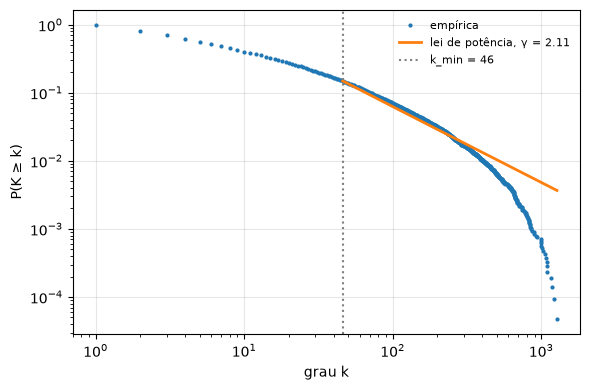

In [4]:
sequencia = list(graus.values())
ajuste = ajustar_lei_de_potencia(sequencia)
comparacao = comparar_distribuicoes(sequencia)
ccdf = calcular_ccdf(distribuir_graus(graus))
cabecalho = ["medida", "código próprio", "pacote powerlaw"]
linhas = [
    ["γ", f"{ajuste.gama:.4f}", f"{comparacao.gama:.4f}"],
    ["k_min", ajuste.k_min, comparacao.k_min],
    ["vértices na cauda", f"{ajuste.n_cauda} ({ajuste.n_cauda / n:.1%})", ""],
    ["distância KS", f"{ajuste.distancia_ks:.4f}", ""],
    ["R contra lognormal (p)", "", f"{comparacao.razao_lognormal:.1f} (p = {comparacao.p_lognormal:.1e})"],
    ["R contra truncada (p)", "", f"{comparacao.razao_truncada:.1f} (p = {comparacao.p_truncada:.1e})"],
]
display(Markdown(formatar_markdown(cabecalho, linhas)))
with open(DIR_RESULTADOS / "parte3_lei_potencia.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)
figura = plotar_ccdf_com_ajuste(ccdf, ajuste.gama, ajuste.k_min, ccdf[ajuste.k_min])
salvar_figura(figura, DIR_IMAGENS / "parte3_lei_potencia")

**Resposta Q2: a cauda é pesada, mas não é uma lei de potência pura.**

- **Ajuste.** O MLE próprio coincide com o pacote `powerlaw` até a 4ª casa: $\hat\gamma = 2{,}11$
  com $k_{min} = 46$. A cauda tem 3.180 vértices (15%), e a distância KS é 0,056.
  - Um γ entre 2 e 3 é típico de redes com hubs: a média é finita, mas a variância cresce com $n$.

- **Teste de razão de verossimilhança.** O sinal de $R$ indica a distribuição favorecida: $R > 0$
  favorece a lei de potência, e $R < 0$ favorece a alternativa.
  - Contra a **lognormal**: $R = -102$, com $p \approx 10^{-20}$.
  - Contra a **lei de potência truncada**: $R = -121$, com $p \approx 0$.
  - Nos dois casos, a alternativa explica a cauda **muito melhor**.

- **Na figura**, a CCDF é côncava em log-log: ela cai mais rápido que a reta nos graus mais altos.
  Isso já se via na Parte I.

- **Por que o corte existe?** Ele vem da própria modelagem:
  - o **T2** limita $k_u \le 50$, então nenhum usuário cria um clique gigante;
  - o **backbone $w \ge 2$** exige co-avaliação repetida, o que limita o grau dos jogos mais
    populares (o maior grau é 1.274, só 6% de $n$);
  - a lognormal é o resultado típico de processos multiplicativos, como popularidade vezes
    nicho vezes plataforma.

- **Conclusão:** há "hubs", como o Apêndice B descreve, mas a afirmação defensável é
  *heavy-tailed, melhor descrita por lognormal ou lei de potência truncada*, e não $P(k) \sim k^{-\gamma}$.

## Q3. O grafo é robusto?

**Apêndice C.** A política para desconexão é trabalhar na LCC, que já é a saída do ETL (T6).
São removidos $r = \lceil 0{,}05\,n \rceil$ vértices.

**Métricas medidas após a remoção:**
- **A:** $S$ = fração dos restantes na maior componente;
- **B:** número de componentes;
- **C:** $L$ dentro da maior componente (100 origens);
- **D:** fração de vértices isolados.

**Estratégias:**
- **(a) aleatória:** $T = 30$ sorteios independentes;
- **(b) ataque:** ranking **fixo**, calculado uma vez no grafo intacto, com duas centralidades:
  - grau, que remove hubs;
  - betweenness exata, que remove os vértices-ponte.

In [5]:
r = calcular_r(n)
aleatoria = remover_ao_acaso(adjacencia, r, 30, N_ORIGENS, config.SEED)
intermediacao = calcular_intermediacao(adjacencia)
rankings = {"grau": ordenar_por_centralidade(graus), "betweenness": ordenar_por_centralidade(intermediacao)}
ataques = {nome: medir_robustez(remover_vertices(adjacencia, set(ranking[:r])), N_ORIGENS, config.SEED)
           for nome, ranking in rankings.items()}
print(f"r = {r} vértices removidos de {n:,}")

r = 1065 vértices removidos de 21,284


| métrica | aleatória: média ± DP | IC 95% | ataque por grau | ataque por betweenness |
|---|---|---|---|---|
| A: S | 0.9883 ± 0.0011 | [0.9879; 0.9887] | 0.8864 | 0.8647 |
| B: componentes | 213.1000 ± 20.8150 | [205.6516; 220.5484] | 2055.0000 | 2381.0000 |
| C: L | 3.7159 ± 0.0577 | [3.6953; 3.7366] | 5.0567 | 5.2847 |
| D: isolados | 0.0097 ± 0.0010 | [0.0093; 0.0100] | 0.0937 | 0.1071 |

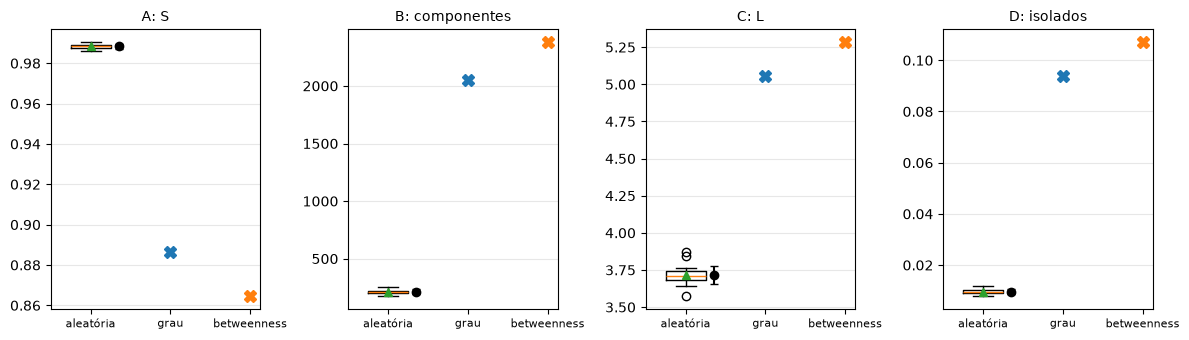

In [6]:
metricas = {"A: S": "maior_componente", "B: componentes": "componentes",
            "C: L": "caminho_medio", "D: isolados": "fracao_isolados"}
cabecalho = ["métrica", "aleatória: média ± DP", "IC 95%", "ataque por grau", "ataque por betweenness"]
linhas = []
for rotulo, campo in metricas.items():
    e = estimar_media_com_ic([getattr(x, campo) for x in aleatoria])
    linhas.append([rotulo, f"{e.media:.4f} ± {e.desvio_padrao:.4f}", f"[{e.ic_inferior:.4f}; {e.ic_superior:.4f}]",
                   f"{getattr(ataques['grau'], campo):.4f}", f"{getattr(ataques['betweenness'], campo):.4f}"])
display(Markdown(formatar_markdown(cabecalho, linhas)))
with open(DIR_RESULTADOS / "parte3_robustez.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)
figura = plotar_robustez(
    {rotulo: [getattr(x, campo) for x in aleatoria] for rotulo, campo in metricas.items()},
    {nome: {rotulo: getattr(a, campo) for rotulo, campo in metricas.items()} for nome, a in ataques.items()},
)
salvar_figura(figura, DIR_IMAGENS / "parte3_robustez_boxplot")

**Curva $S(f)$.** Para ver além dos 5%, o mesmo ranking fixo é aplicado de $f = 0$ a $f = 0{,}3$.
Na curva "aleatória", o ranking é uma permutação sorteada com a SEED.

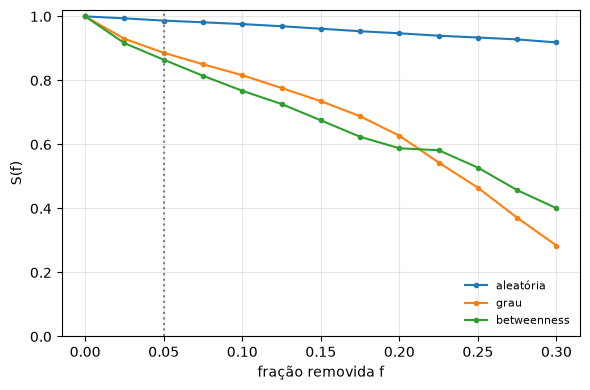

In [7]:
fracoes = [i / 40 for i in range(13)]
aleatorio = sorted(adjacencia)
random.Random(config.SEED).shuffle(aleatorio)
curvas = {"aleatória": medir_curva_de_ataque(adjacencia, aleatorio, fracoes)}
curvas |= {nome: medir_curva_de_ataque(adjacencia, ranking, fracoes) for nome, ranking in rankings.items()}
with open(DIR_RESULTADOS / "parte3_curvas_ataque.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["f", *curvas], ([f, *(c[i] for c in curvas.values())] for i, f in enumerate(fracoes)), fluxo)
salvar_figura(plotar_curvas_de_ataque(fracoes, curvas), DIR_IMAGENS / "parte3_curvas_ataque")

**Resposta Q3.**

**(a) A falha aleatória de 5% não abala o grafo: ele é robusto.**
- $S = 0{,}988 \pm 0{,}001$: 98,8% dos restantes continuam na maior componente.
- Surgem cerca de 213 componentes, quase todas vértices que ficaram isolados (1%).
- $L$ não muda: 3,72, dentro do ruído da estimativa do grafo intacto.
- O motivo é a redundância. Com $\langle k\rangle = 30$, um vértice só se solta se perder todos
  os vizinhos, e isso só acontece com as folhas, que a Parte II já mostrou serem muitas.

**(b) O ataque dirigido faz bem mais estrago, sem destruir o grafo.**

| | aleatória | grau | betweenness |
|---|---|---|---|
| $S$ | 0,988 | 0,886 | **0,865** |
| componentes | 213 | 2.055 (9,6×) | **2.381 (11×)** |
| $L$ | 3,72 | 5,06 | **5,28** |
| isolados | 1,0% | 9,4% | **10,7%** |

- Temos $S_{rand} > S_{cent}$ e $c_{cent} \gg c_{rand}$, o padrão de rede com hubs que o Apêndice C descreve.
- A **betweenness** é o ataque mais eficaz nas quatro métricas. Ela remove os vértices-ponte,
  e não apenas os populares.
- A degradação é "macia": a maior componente segue com 86% dos vértices. O que se perde são as
  **folhas** penduradas nos hubs (os isolados vão de 1% para 11%) e os atalhos (o $L$ sobe 42%).

**Curva $S(f)$:**
- Com remoção aleatória, $S$ cai quase em linha reta: 0,92 em $f = 30\%$.
- Com ataque, $S$ cai rápido: 0,63 (grau) e 0,59 (betweenness) em 20%.
- Depois de cerca de 22%, **o ataque por grau ultrapassa a betweenness** e chega a 0,28 em 30%.
  O ranking fixo de betweenness fica desatualizado: as pontes do grafo intacto já não são as
  pontes do grafo atacado, e os hubs que sobraram passam a segurar o que resta.

## Q4. Descoberta: hubs, pontes e plataformas

Três perguntas:
1. Os vértices de maior grau são os mesmos de maior betweenness?
2. As arestas ligam jogos da mesma plataforma mais do que o acaso explicaria?
3. Depois do ataque, que plataformas se soltam da maior componente?

In [8]:
def listar(ranking, centralidade, quantos=12):
    return [[i + 1, grafo.jogos[v].titulo[:60], grafo.jogos[v].plataforma, f"{centralidade[v]:,.0f}"]
            for i, v in enumerate(ranking[:quantos])]

display(Markdown("**Top 12 por grau**\n\n" + formatar_markdown(["#", "título", "plataforma", "grau"], listar(rankings["grau"], graus))))
display(Markdown("**Top 12 por betweenness**\n\n" + formatar_markdown(["#", "título", "plataforma", "betweenness"], listar(rankings["betweenness"], intermediacao))))
comum = set(rankings["grau"][:r]) & set(rankings["betweenness"][:r])
print(f"sobreposição entre os top r = {r}: {len(comum)} vértices ({len(comum) / r:.1%})")

**Top 12 por grau**

| # | título | plataforma | grau |
|---|---|---|---|
| 1 | Xbox 360 Wireless Controller - Glossy Black | Xbox 360 | 1,274 |
| 2 | Wii | Wii | 1,210 |
| 3 | The Last of Us Remastered - PlayStation 4 | PlayStation 4 | 1,172 |
| 4 | Diablo III | PC | 1,159 |
| 5 | Halo 4 - Xbox 360 (Standard Game) | Xbox 360 | 1,098 |
| 6 | Assassin's Creed | Xbox 360 | 1,090 |
| 7 | Uncharted 4: A Thief's End - PlayStation 4 | PlayStation 4 | 1,084 |
| 8 | Xbox 360 LIVE 1600 Points | Xbox One | 1,070 |
| 9 | Assassin's Creed - Playstation 3 | PlayStation 3 | 1,062 |
| 10 | Xbox One Play and Charge Kit | Xbox 360 | 1,030 |
| 11 | Destiny - Standard Edition - PlayStation 4 | PlayStation 4 | 1,008 |
| 12 | Mario Kart 8 - Nintendo Wii U | Kids & Family | 994 |

**Top 12 por betweenness**

| # | título | plataforma | betweenness |
|---|---|---|---|
| 1 | Wii | Wii | 7,902,184 |
| 2 | Big Kahuna Reef [Download] | PC | 5,459,243 |
| 3 | Diablo III | PC | 5,432,036 |
| 4 | Xbox 360 Wireless Controller - Glossy Black | Xbox 360 | 5,415,635 |
| 5 | Nintendo DS Lite Polar White | Nintendo DS | 5,227,484 |
| 6 | New Super Mario Bros. Wii | Kids & Family | 4,698,585 |
| 7 | Halo - Xbox | Retro Gaming & Microconsoles | 4,463,447 |
| 8 | Xbox 360 LIVE 1600 Points | Xbox One | 3,475,835 |
| 9 | Final Fantasy X | Retro Gaming & Microconsoles | 3,331,402 |
| 10 | Assassin's Creed | Xbox 360 | 3,222,340 |
| 11 | New Super Mario Bros | Nintendo DS | 3,129,684 |
| 12 | Yoshi amiibo (Super Smash Bros Series) | Nintendo 3DS & 2DS | 3,056,209 |

sobreposição entre os top r = 1065: 695 vértices (65.3%)


In [9]:
observada, esperada = medir_mistura_de_plataformas(grafo.pesos, grafo.jogos)
print(f"arestas entre jogos da mesma plataforma: {observada:.1%} (esperado ao acaso: {esperada:.1%}, {observada / esperada:.1f}×)")
for nome, ranking in rankings.items():
    restante = remover_vertices(adjacencia, set(ranking[:r]))
    soltas = [c for c in componentes_conexas(restante)[1:] if len(c) >= 5]
    print(f"\nataque por {nome}: {len(soltas)} componentes com 5 ou mais vértices além da maior; as 6 maiores:")
    for c in soltas[:6]:
        print(f"  {len(c):>4} vértices: {resumir_plataformas(c, grafo.jogos, 2)}")

arestas entre jogos da mesma plataforma: 52.4% (esperado ao acaso: 11.5%, 4.5×)



ataque por grau: 8 componentes com 5 ou mais vértices além da maior; as 6 maiores:
    12 vértices: [('Wii U', 7), ('Kids & Family', 5)]
    10 vértices: [('Retro Gaming & Microconsoles', 10)]
     8 vértices: [('Kids & Family', 4), ('Nintendo 3DS & 2DS', 3)]
     5 vértices: [('PC', 5)]
     5 vértices: [('PlayStation 3', 5)]
     5 vértices: [('PC', 5)]

ataque por betweenness: 15 componentes com 5 ou mais vértices além da maior; as 6 maiores:
    11 vértices: [('Digital Games', 6), ('PC', 5)]
     9 vértices: [('PC', 8), ('Kids & Family', 1)]
     6 vértices: [('Xbox 360', 6)]
     5 vértices: [('Retro Gaming & Microconsoles', 5)]
     5 vértices: [('Retro Gaming & Microconsoles', 5)]
     5 vértices: [('PC', 5)]


**Resposta Q4: a descoberta mais interessante é que o grafo "sabe" a plataforma de cada jogo, e quem conecta as plataformas não são os mais populares.**

1. **A homofilia por plataforma é forte.**
   - 52,4% das arestas ligam jogos da mesma plataforma, contra 11,5% esperados ao acaso:
     **4,5 vezes mais**.
   - Isso acontece mesmo com o ruído dos rótulos ("Retro Gaming" e "Kids & Family" juntam
     várias plataformas), então o valor real deve ser ainda maior.
   - É isso que explica a Q1: o $C$ alto vem da projeção, mas o $L$ mais longo que o nulo vem
     dessa segregação.
   - O grafo reconstrói o "mapa de consoles" **só a partir de quem avaliou o quê**, sem nunca
     ver o rótulo. A Parte I já mostrava isso no desenho do núcleo de 300 vértices.

2. **Hubs e pontes são parentes, mas não são os mesmos vértices.**
   - Os top $r$ por grau e por betweenness coincidem em 65%.
   - Os **hubs de grau** são best-sellers de geração recente e acessórios: o controle do
     Xbox 360, The Last of Us, Halo 4.
   - As **pontes de betweenness** são **consoles e títulos que cruzam gerações e públicos**: o
     próprio Wii, o Nintendo DS Lite, New Super Mario Bros., Halo do Xbox original, Final
     Fantasy X e um amiibo.
   - O caso mais curioso é **Big Kahuna Reef [Download]**, um jogo casual de PC que não está
     no top de grau mas é a 2ª maior ponte. Ele liga o público casual e família ao resto do
     catálogo de PC.

3. **O ataque solta "ilhas" de plataforma.**
   - As componentes de 5 ou mais vértices que se separam são quase homogêneas: só Wii U e
     família, só retro, só PC, só PS3, só Xbox 360.
   - Remover as pontes desfaz os elos entre plataformas, e os nichos se separam.

**Em resumo:** o grafo é um *small-world* de comunidades (plataformas) costuradas por
consoles e clássicos que atravessam gerações. A Parte II acrescenta outro achado: as arestas
mais fortes são o mesmo produto anunciado com ASINs diferentes.

## Q5 (extra): o grafo se aproxima de algum modelo clássico?

**Nenhum dos três clássicos descreve o grafo sozinho. Cada um acerta uma parte.**

| propriedade | ER | Barabási–Albert | Watts–Strogatz | grafo real |
|---|---|---|---|---|
| $C$ alto | ✗ ($\approx 0{,}0014$) | ✗ ($C \to 0$ com $n$) | ✓ | ✓ 0,32 |
| $L$ curto | ✓ | ✓ | ✓ | ✓ 3,8 |
| cauda pesada | ✗ (Poisson) | ✓ ($\gamma = 3$) | ✗ (graus quase iguais) | ✓, mas lognormal ou truncada |
| comunidades | ✗ | ✗ | ✗ (só localidade) | ✓ (plataformas) |

- **ER** fica descartado pela clusterização (229 vezes menor) e pela cauda.
- **BA** acerta os hubs. Porém prevê lei de potência pura com $\gamma = 3$ (aqui são 2,1 e com
  corte) e $C$ quase nulo.
- **WS** é o mais próximo no par ($C$, $L$), que é a definição de small-world. Porém tem graus
  homogêneos, e aqui o maior grau é 42 vezes a média.

**O modelo que de fato reproduz o grafo** é o que usamos como nulo: a projeção de um bipartido
aleatório com os graus observados. Ele acerta $C$ e a cauda. Somando a ele a homofilia por
plataforma, chega-se também ao $L$ e às comunidades. Ou seja, o grafo é melhor entendido pelo
**mecanismo que o gera** (cliques de usuários sobrepostos) do que por qualquer um dos três modelos clássicos.

## Sensibilidade ao limiar de coavaliação

Mantemos os mesmos 36.626 produtos e os mesmos pares usuário–produto depois de T3. Variamos só o peso mínimo das arestas. Produtos que ficam sem aresta entram na contagem como componentes de tamanho 1.

Este passo também precisa do arquivo bruto. Sem ele, a célula mostra a tabela salva em `results/parte3_sensibilidade.csv` pela última execução com os dados brutos.

In [10]:
from src.etl.projecao import (
    agrupar_por_usuario, podar_arestas_fracas, projetar_coavaliacao,
)

ARQ_SENSIBILIDADE = DIR_RESULTADOS / "parte3_sensibilidade.csv"
if DADOS_BRUTOS:
    with config.ARQ_AVALIACOES.open(encoding="utf-8", newline="") as fluxo:
        pares, _ = tratar_bipartido(
            ler_pares_avaliacao(fluxo), config.CAP_USUARIO, config.MIN_AVALIACOES_JOGO
        )

    produtos = {produto for _, produto in pares}
    pesos = projetar_coavaliacao(agrupar_por_usuario(pares))
    del pares  # a comparação daqui em diante usa só os pesos projetados

    cabecalho = [
        "peso mínimo", "arestas", "componentes", "isolados", "vértices LCC",
        "arestas LCC", "% dos produtos na LCC",
    ]
    linhas = []
    for peso_minimo in (1, config.MIN_PESO, 3):
        backbone = podar_arestas_fracas(pesos, peso_minimo)
        vizinhos = montar_adjacencia(backbone)
        for produto in produtos:
            vizinhos.setdefault(produto, set())
        componentes = componentes_conexas(vizinhos)
        lcc = componentes[0]
        linhas.append([
            peso_minimo, len(backbone), len(componentes),
            sum(not adj for adj in vizinhos.values()), len(lcc),
            sum(len(vizinhos[v]) for v in lcc) // 2, round(100 * len(lcc) / len(produtos), 2),
        ])

    display(Markdown(formatar_markdown(cabecalho, linhas)))
    with open(ARQ_SENSIBILIDADE, "w", encoding="utf-8") as fluxo:
        escrever_tabela(cabecalho, linhas, fluxo)
else:
    with open(ARQ_SENSIBILIDADE, encoding="utf-8") as fluxo:
        tabela = list(csv.reader(fluxo))
    display(Markdown(formatar_markdown(tabela[0], tabela[1:])))

| peso mínimo | arestas | componentes | isolados | vértices LCC | arestas LCC | % dos produtos na LCC |
|---|---|---|---|---|---|---|
| 1 | 2509461 | 425 | 421 | 36199 | 2509458 | 98.83 |
| 2 | 321127 | 14976 | 14677 | 21284 | 320742 | 58.11 |
| 3 | 123593 | 23835 | 23373 | 12164 | 122922 | 33.21 |

Com um único avaliador em comum, a maior componente contém 98,83% dos produtos, mas muitas arestas dependem de uma só pessoa. Exigir dois avaliadores mantém 58,11% dos produtos na maior componente. Com três, a cobertura cai para 33,21%. Por isso usamos dois como compromisso entre apoio de mais de um avaliador e cobertura. As medidas de pequeno mundo e robustez acima se referem ao recorte com peso mínimo dois.